# **실습 개요**

여러분은 한 교육 컨설팅 회사의 데이터 분석팀에 합류했습니다. <br>
이 회사는 학생들의 학습 습관 데이터를 바탕으로
최종 학업 성취도(Performance Index)를 예측하는 모델을 만들어,<br>학생들에게 맞춤형 학습 전략을 제안하려고 합니다.

## **데이터셋 설명**

학생들의 학습 습관과 최종 학업 성취도(Performance Index)에 대한 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| Hours Studied | 하루 평균 학습 시간 (시간) |
| Previous Scores | 이전 시험 점수 (0~100) |
| Extracurricular Activities | 과외활동 참여 여부 (Yes/No) |
| Sleep Hours | 하루 평균 수면 시간 (시간) |
| Sample Question Papers Practiced | 풀어본 모의고사(기출문제) 수 |
| Weekly Study Hours | 주간 총 학습 시간 (시간) |
| Performance Index | **[target]** 최종 학업 성취도 지수 (0~100, 값이 클수록 우수) |

## **데이터셋 URL**
url : https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_performance.csv


## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Weekly Study Hours,Performance Index
0,6,92.0,Yes,9.0,4.0,42.2,86
1,1,54.0,No,7.0,7.0,6.9,28
2,7,45.0,Yes,6.0,6.0,49.3,38
3,5,70.0,Yes,4.0,6.0,35.6,55
4,1,47.0,Yes,5.0,0.0,6.9,18


**Q1. 데이터의 shape(행, 열 개수)을 확인하세요.**

In [3]:
df.shape

(1200, 7)

**Q2. 각 컬럼의 기본적인 정보를 확인하세요.**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     1200 non-null   int64  
 1   Previous Scores                   1164 non-null   float64
 2   Extracurricular Activities        1200 non-null   object 
 3   Sleep Hours                       1116 non-null   float64
 4   Sample Question Papers Practiced  1140 non-null   float64
 5   Weekly Study Hours                1200 non-null   float64
 6   Performance Index                 1200 non-null   int64  
dtypes: float64(4), int64(2), object(1)
memory usage: 65.8+ KB


**Q3. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [6]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Weekly Study Hours,Performance Index
count,1200.000000,1164.000000,1116.000000,1140.000000,1200.000000,1200.000000
mean,5.150000,68.880584,6.419355,4.497368,36.065417,54.829167
std,2.965326,17.195262,1.686066,2.910577,20.754526,19.941616
min,1.000000,40.000000,4.000000,0.000000,6.200000,-12.000000
25%,3.000000,54.000000,5.000000,2.000000,20.800000,40.000000
50%,5.000000,68.000000,6.000000,5.000000,35.100000,54.000000
75%,7.000000,83.250000,8.000000,7.000000,49.200000,70.000000
max,25.000000,99.000000,9.000000,9.000000,175.000000,130.000000


## **2. 데이터 분석하기**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.

colab에서 csv 파일 다운로드하기
```
from google.colab import files
files.download("submission.csv")
```

### **2-1. 데이터 탐색**

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**

Extracurricular Activities 여부에 따른 Peformance Index의 평균을 소수점 2자리까지 구하시오.

In [13]:
df.groupby('Extracurricular Activities')['Performance Index'].mean().round(2)

,Performance Index
Extracurricular Activities,
No,53.99
Yes,55.63


**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 학습 시간 기준 상위 10명의 평균 Performance Index를 소수점 2자리까지 확인하세요.
- 수면 시간이 6시간 미만인 학생들의 평균 Performance Index를 소수점 2자리까지 확인하세요.
- Performance Index가 0보다 작거나 100보다 큰(상식적으로 불가능한) 행이 몇 개인지 확인하세요.

각 값을 "ans" 열에 순서대로 저장하여 제출합니다.

In [129]:
# 결측치를 제외하고 올바른 기초 연산을 수행하기 위해 데이터를 원본 기준으로 연산합니다.
# 1. 학습 시간 기준 상위 10명의 평균 Performance Index
top10_performance = round(df.sort_values(by='Hours Studied', ascending=False)['Performance Index'].head(10).mean(), 2)

# 2. 수면 시간이 6시간 미만인 학생들의 평균 Performance Index (결측치는 자동으로 제외됨)
sleep_less_than_6 = round(df[df['Sleep Hours'] < 6]['Performance Index'].mean(), 2)

# 3. Performance Index가 0보다 작거나 100보다 큰 상식 밖의 행 개수
perf_0_100 = df[(df['Performance Index'] < 0) | (df['Performance Index'] > 100)].shape[0]

print("상위 10명 평균 성적:", top10_performance)
print("수면 6시간 미만 평균 성적:", sleep_less_than_6)
print("범위 초과 데이터 개수:", perf_0_100)

상위 10명 평균 성적: 49.7
수면 6시간 미만 평균 성적: 53.35
범위 초과 데이터 개수: 0


In [54]:
csv = pd.DataFrame({'ans': [top10_performance, sleep_less_than_6, perf_0_100]})
csv.to_csv('submission.csv', index=False)

from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Q5. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- Extracurricular Activities 여부에 따른 풀어본 문제집 수의 평균과 중앙값을 함께 비교하세요.
- 두 값 모두 소수점 2자리까지로 정리해 주세요.

In [59]:
df.groupby('Extracurricular Activities')['Sample Question Papers Practiced'].agg(['mean', 'median']).round(2)

,mean,median
Extracurricular Activities,,
No,4.44,5.0
Yes,4.55,5.0


### **2-2. 데이터 시각화**

**Q1. Performance Index의 분포를 히스토그램으로 시각화하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

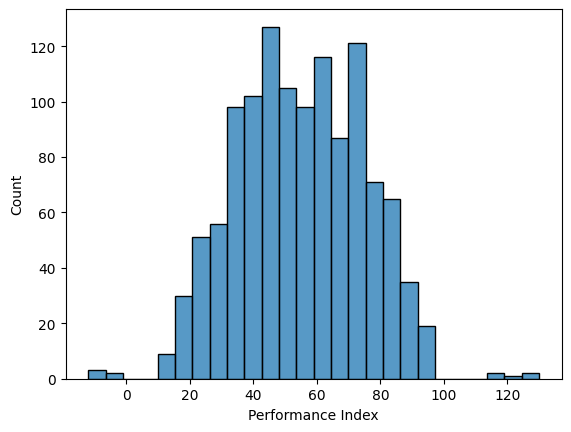

In [61]:
sns.histplot(df['Performance Index'])
plt.show()

# 학업 성적은 가운데에 가장 많이 분포

**Q2. Hours Studied와 Performance Index의 관계를 산점도로 시각화하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

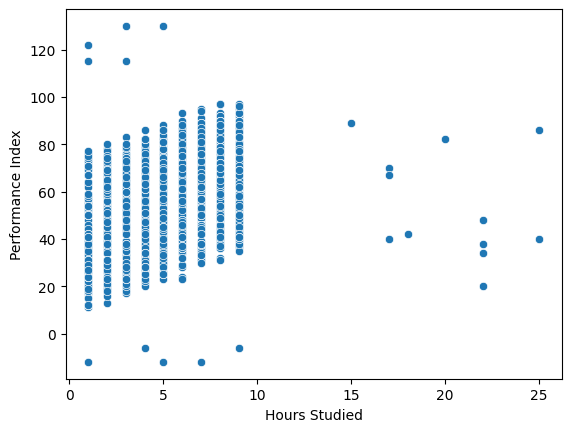

In [62]:
sns.scatterplot(x='Hours Studied', y='Performance Index', data=df)
plt.show()

**Q3. Hours Studied와 Weekly Study Hours를 산점도로 시각화하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

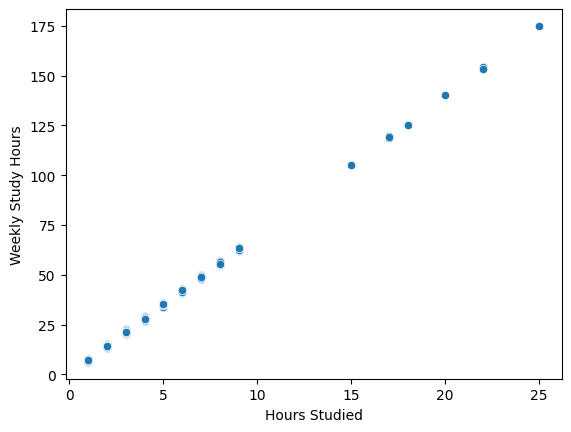

In [63]:
sns.scatterplot(x='Hours Studied', y='Weekly Study Hours', data=df)
plt.show()

**Q3. Extracurricular Activities 여부별 Performance Index를 박스플롯(box plot)으로 비교하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

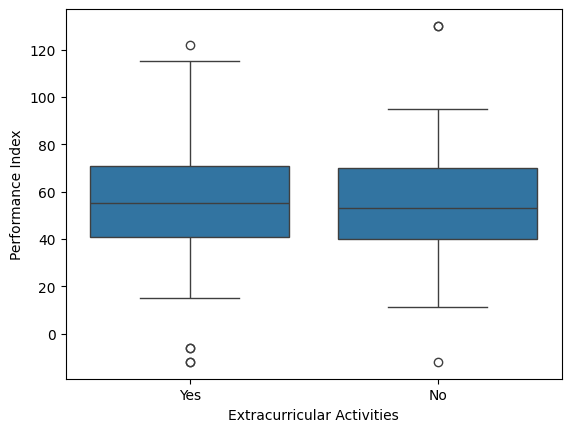

In [64]:
sns.boxplot(x='Extracurricular Activities', y='Performance Index', data=df)
plt.show()

**Q5. 공부 시간의 이상치를 박스플롯으로 확인하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

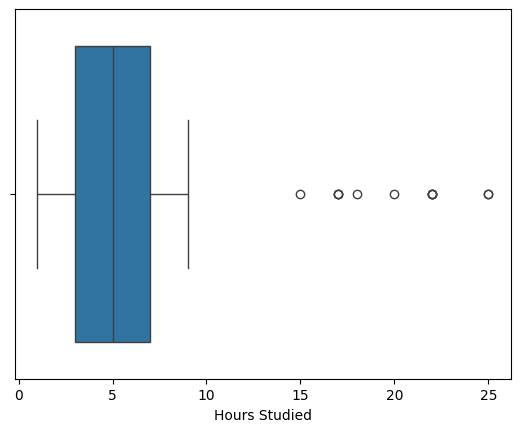

In [65]:
sns.boxplot(x=df['Hours Studied'])
plt.show()

## **3. 데이터 전처리하기**

In [157]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Weekly Study Hours,Performance Index
0,6,92.0,Yes,9.0,4.0,42.2,86
1,1,54.0,No,7.0,7.0,6.9,28
2,7,45.0,Yes,6.0,6.0,49.3,38
3,5,70.0,Yes,4.0,6.0,35.6,55
4,1,47.0,Yes,5.0,0.0,6.9,18


### **3.1. 이상치 처리하기 1**

**Q1. 애초에 말도 안되는 데이터는 제거를 하자.**
- Performance Index는 음수가 되거나, 100을 초과할 수 없다.
- 공부 시간은 음수가 될 수 없다.

In [168]:
df.drop(df[df['Performance Index'] < 0].index, inplace=True)
df.drop(df[df['Performance Index'] > 100].index, inplace=True)
df.drop(df[df['Hours Studied'] < 0].index, inplace=True)

### **3-2. 데이터 분리하기**

**Q1. Performance Index를 target으로 하여 train과 테스트 데이터를 분리합니다.**
- 비율 : 7(학습):3(테스트)
- random_state = 101

In [169]:
from sklearn.model_selection import train_test_split

In [170]:
X = df.drop('Performance Index', axis=1)
y = df['Performance Index']

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=.3, random_state=101)

### **3-3. 결측치 처리하기**

**Q1. train 데이터의 결측치 개수를 확인합니다.**

In [171]:
train_X.isnull().sum()

,0
Hours Studied,0
Previous Scores,23
Extracurricular Activities,0
Sleep Hours,60
Sample Question Papers Practiced,47
Weekly Study Hours,0


**Q2. Previous Scores, Sleep Hours, Sample Question Papers Practiced의 결측치를 train 데이터의 중앙값(median)으로 대체하세요.**
- 이때 test 데이터에도 동일한(train 기준) 값을 사용하세요

In [172]:
cols = ['Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']

medians = train_X[cols].median()

train_X[cols] = train_X[cols].fillna(medians)
test_X[cols] = test_X[cols].fillna(medians)

print(train_X.isnull().sum())
print(test_X.isnull().sum())

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Weekly Study Hours                  0
dtype: int64
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Weekly Study Hours                  0
dtype: int64


### **3-4. 이상치 처리하기 2**

**Q1. IQR을 통해 각 column에 outlier가 몇 개씩이나 있는지를 확인해보세요.**

In [173]:
num_cols = train_X.select_dtypes(include='number').columns

Q1 = train_X[num_cols].quantile(0.25)
Q3 = train_X[num_cols].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - (1.5*IQR)
upper = Q3 + (1.5*IQR)

outlier_count = ((train_X[num_cols] < lower) | (train_X[num_cols] > upper)).sum()
print(outlier_count)

Hours Studied                       8
Previous Scores                     0
Sleep Hours                         0
Sample Question Papers Practiced    0
Weekly Study Hours                  8
dtype: int64


**Q2. 이상치가 존재하는 열들읠 행 정보들을 삭제합니다.**
- Hours Studied, Weekly Study Hours열에 존재하는 이상치 행들의 index를 추출하여, 삭제합니다.

In [174]:
outliers_idx = train_X[
    (train_X['Hours Studied'] < lower['Hours Studied'])
    | (train_X['Hours Studied'] > upper['Hours Studied'])
    | (train_X['Weekly Study Hours'] < lower['Weekly Study Hours'])
    | (train_X['Weekly Study Hours'] > upper['Weekly Study Hours'])
].index

print(outliers_idx)
train_X = train_X.drop(outliers_idx)
train_y = train_y.drop(outliers_idx)

Index([133, 978, 908, 1190, 162, 411, 704, 512], dtype='int64')


In [175]:
outlier_count = ((train_X[num_cols] < lower) | (train_X[num_cols] > upper)).sum()
print(outlier_count)

Hours Studied                       0
Previous Scores                     0
Sleep Hours                         0
Sample Question Papers Practiced    0
Weekly Study Hours                  0
dtype: int64


**Q3. 이상치 제거 검증을 위해 boxplot을 다시 한번 그려 봅시다.**

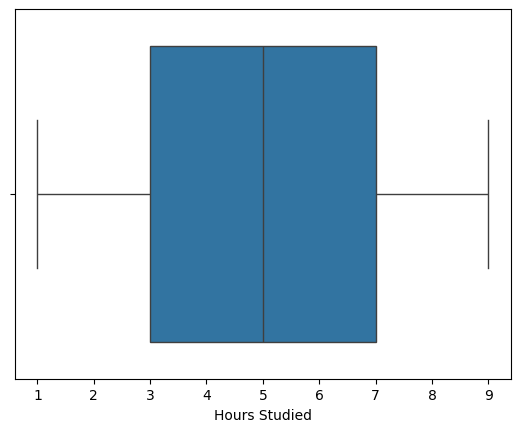

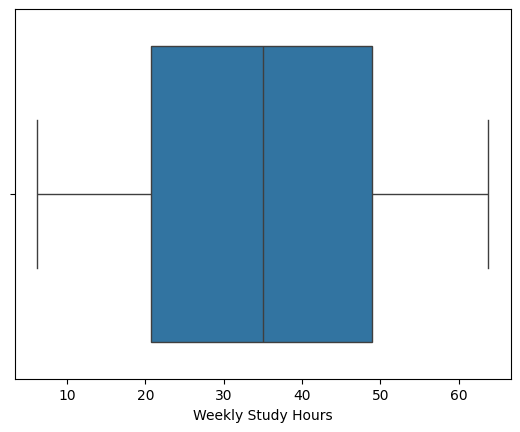

In [176]:
sns.boxplot(x=train_X['Hours Studied'])
plt.show()

sns.boxplot(x=train_X['Weekly Study Hours'])
plt.show()

### **3-5. Feature Encoding**

**Q. Extracurricular Activities 컬럼을 인코딩하세요.**

Binary (0 또는 1)인 상황이니, Label Enoder를 활용하여 인코딩합니다.

In [177]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

train_X['Extracurricular Activities'] = le.fit_transform(train_X['Extracurricular Activities'])
test_X['Extracurricular Activities'] = le.transform(test_X['Extracurricular Activities'])

In [178]:
train_X.shape

(825, 6)

## **4. 모델 학습 및 평가**

### **4-1. 모델 학습**

**Q1. Linear Regression 모델을 만들고, 학습시키세요.**

In [179]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(train_X, train_y)

LinearRegression()

### **4-2. 예측**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

In [181]:
y_pred = lr.predict(test_X)

### **4-3. 모델 평가**

**Q1. MSE, RMSE, R2 Score를 이용해 모델 성능을 평가하세요.**

In [185]:
from sklearn.metrics import mean_squared_error, r2_score

print(f"MSE: {mean_squared_error(test_y, y_pred)}")
print(f"RMSE: {np.sqrt(mean_squared_error(test_y, y_pred))}")
print(f"R2 Score: {r2_score(test_y, y_pred)}")

MSE: 31.18689613516716
RMSE: 5.584522910255375
R2 Score: 0.9053458030706335
